Question 01:Circle Detection Using Laplacian of Gaussian (LoG)

In [91]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
%matplotlib inline

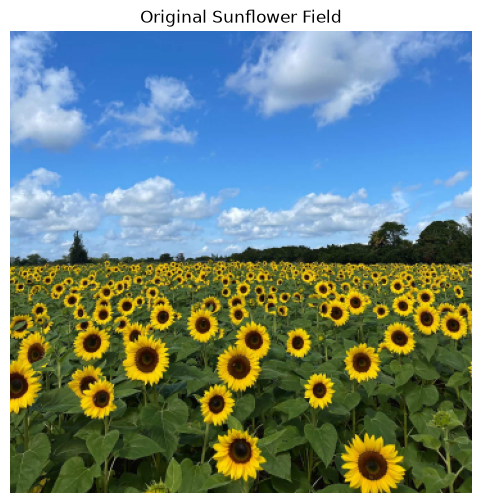

In [92]:
# Load image as instructed
image = cv.imread(
    "images/the_berry_farms_sunflower_field.jpeg",
    cv.IMREAD_REDUCED_COLOR_4
)

if image is None:
    raise FileNotFoundError("Sunflower image not found")

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
gray = gray.astype(np.float32) / 255.0

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Original Sunflower Field")
plt.axis("off")
plt.show()

In [93]:
#Apply LoG at different scales
sigmas = np.arange(2, 16, 1)

responses = []

for sigma in sigmas:
    log = gaussian_laplace(gray, sigma=sigma)

    # Scale-normalized squared LoG response
    response = (sigma**2 * log)**2

    responses.append(response)

scale_space = np.stack(responses, axis=0)

In [94]:
# Find local maxima in space and scale
local_max = maximum_filter(scale_space,size=(3, 9, 9))
# Response threshold
threshold = 0.15 * scale_space.max()
peaks = ((scale_space == local_max) & (scale_space > threshold))
scale_indices, ys, xs = np.where(peaks)
# Convert sigma to radius
radii = np.sqrt(2) * sigmas[scale_indices]
print("Number of detected blobs:", len(radii))

Number of detected blobs: 253


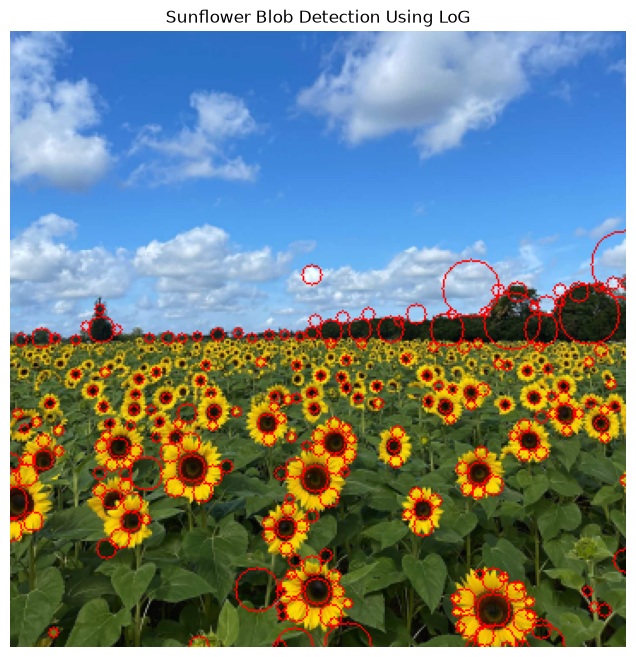

In [95]:
result = cv.cvtColor(image, cv.COLOR_BGR2RGB).copy()

for x, y, r in zip(xs, ys, radii):
    cv.circle(result,(int(x), int(y)),int(round(r)),(255, 0, 0),1)

plt.figure(figsize=(12, 8))
plt.imshow(result)
plt.title("Sunflower Blob Detection Using LoG")
plt.axis("off")
plt.show()

In [96]:
# Sort circles by radius, largest first
order = np.argsort(radii)[::-1]

print("Sigma range:", sigmas.min(), "to", sigmas.max())

print("\nLargest detected circles:")
print("Center X | Center Y | Radius | Sigma")

for i in order[:10]:
    print(
        f"{xs[i]:8d} | "
        f"{ys[i]:8d} | "
        f"{radii[i]:6.2f} | "
        f"{sigmas[scale_indices[i]]:5.1f}"
    )

Sigma range: 2 to 15

Largest detected circles:
Center X | Center Y | Radius | Sigma
     359 |      136 |  19.80 |  14.0
     338 |      165 |  18.38 |  13.0
     293 |      169 |  16.97 |  12.0
     269 |      150 |  16.97 |  12.0
     197 |      359 |  14.14 |  10.0
     311 |      359 |  12.73 |   9.0
     283 |      359 |  12.73 |   9.0
     144 |      326 |  12.73 |   9.0
     166 |      359 |  11.31 |   8.0
     282 |      338 |   9.90 |   7.0


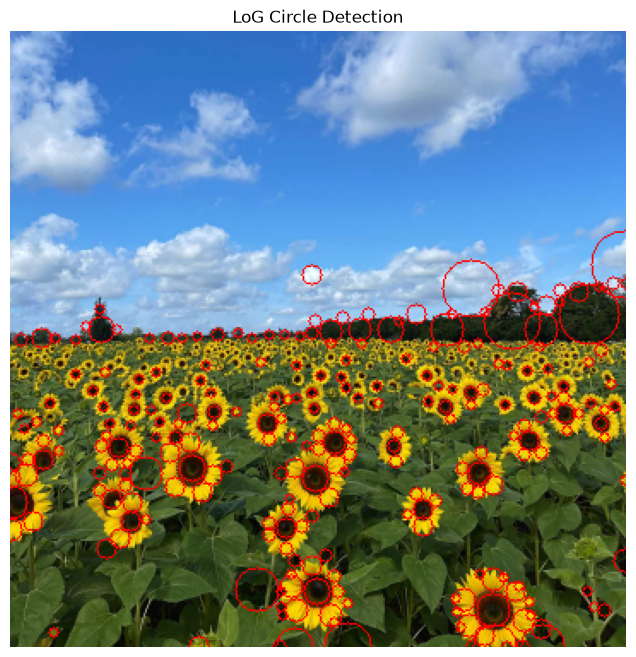

In [97]:
import os

os.makedirs("results", exist_ok=True)

plt.figure(figsize=(12, 8))
plt.imshow(result)
plt.title("LoG Circle Detection")
plt.axis("off")

plt.savefig(
    "results/q1_detected_circles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Question 02: Line and Circle Fitting Using RANSAC

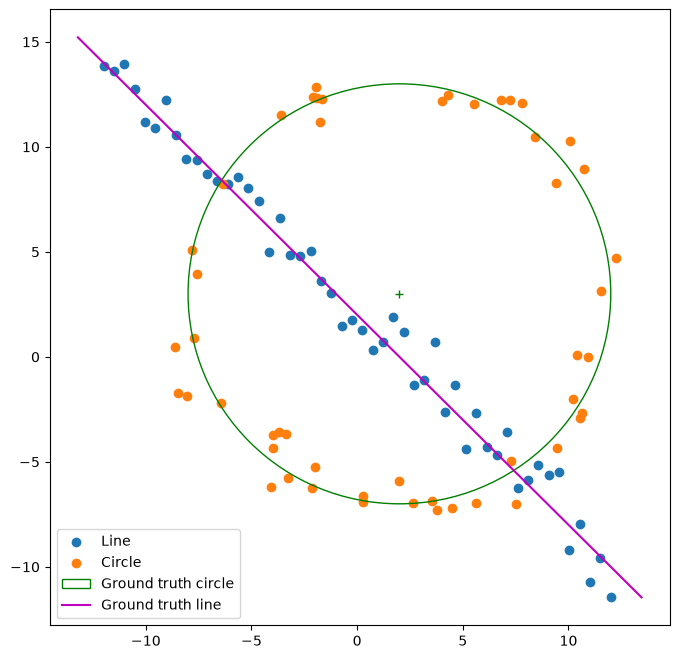

In [98]:
# Generation of a Noisy Point Set Conforming to a Line and a Circle

import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt
#import tikzplotlib

# np.random.seed(0)

N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3  # Center

s = r / 16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s * np.random.randn(half_n)

x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.
m, b = -1, 2

x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)

X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))  # All points

fig, ax = plt.subplots(1, 1, figsize=(8, 8))

ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')

circle_gt = plt.Circle(
    (x0_gt, y0_gt), r,
    color='g', fill=False,
    label='Ground truth circle'
)

ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, '+', color='g')

x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b

plt.plot(x_, y_, color='m', label='Ground truth line')
plt.legend()
plt.show()

In [99]:
# Q2(a) - Line fitting using RANSAC

def fit_line(p1, p2):
    dx = p2[0] - p1[0]
    dy = p2[1] - p1[1]

    length = np.sqrt(dx**2 + dy**2)

    if length < 1e-10:
        return None

    # Unit normal vector
    a = -dy / length
    b = dx / length

    d = a*p1[0] + b*p1[1]

    return np.array([a, b, d])


def line_error(points, model):
    a, b, d = model

    return np.abs(a*points[:, 0] + b*points[:, 1] - d)


# RANSAC parameters
line_threshold = 1.0
line_iterations = 2000
minimum_line_inliers = 30

best_count = 0
best_line_model = None

for i in range(line_iterations):

    # Select two random points
    indices = np.random.choice(len(X), 2, replace=False)
    sample = X[indices]

    # Estimate line
    model = fit_line(sample[0], sample[1])

    if model is None:
        continue

    # Find inliers
    errors = line_error(X, model)
    inliers = errors < line_threshold

    count = np.sum(inliers)

    # Save best model
    if count > best_count:
        best_count = count
        best_line_model = model.copy()
        best_line_sample = sample.copy()
        best_line_inliers = inliers.copy()


if best_count < minimum_line_inliers:
    raise RuntimeError("Not enough line inliers found")


# Final line is the best RANSAC model
final_line = best_line_model.copy()

a, b, d = final_line

print("Estimated line [a, b, d]:", final_line)
print("Number of line inliers:", best_count)
print("Normal magnitude:", np.sqrt(a**2 + b**2))

Estimated line [a, b, d]: [0.70237912 0.71180304 1.48498083]
Number of line inliers: 47
Normal magnitude: 1.0


In [100]:
#Q2(b): Remove line inliers and fit the circle
# Q2(b) - Remove line inliers

remaining_points = X[~best_line_inliers]

print("Total points:", len(X))
print("Points remaining:", len(remaining_points))


def fit_circle(points):
    p1, p2, p3 = points

    A = 2 * np.array([
        p2 - p1,
        p3 - p1
    ])

    B = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    # Reject collinear points
    if abs(np.linalg.det(A)) < 1e-8:
        return None

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1 - center)

    return np.array([center[0], center[1], radius])


def circle_error(points, model):
    xc, yc, r = model

    distance = np.sqrt(
        (points[:, 0] - xc)**2 +
        (points[:, 1] - yc)**2
    )

    return np.abs(distance - r)


# Circle RANSAC parameters
circle_threshold = 1.0
circle_iterations = 2000
minimum_circle_inliers = 25

best_circle_count = 0
best_circle_model = None

for i in range(circle_iterations):

    indices = np.random.choice(
        len(remaining_points), 3, replace=False
    )

    sample = remaining_points[indices]
    model = fit_circle(sample)

    if model is None:
        continue

    errors = circle_error(remaining_points, model)
    inliers = errors < circle_threshold

    count = np.sum(inliers)

    if count > best_circle_count:
        best_circle_count = count
        best_circle_model = model.copy()
        best_circle_sample = sample.copy()
        best_circle_inliers = inliers.copy()


if best_circle_count < minimum_circle_inliers:
    raise RuntimeError("Not enough circle inliers found")


# Refine circle using scipy.optimize.minimize

circle_points = remaining_points[best_circle_inliers]

def circle_objective(params):
    errors = circle_error(circle_points, params)
    return np.sum(errors**2)


result = minimize(
    circle_objective,
    best_circle_model,
    method="L-BFGS-B",
    bounds=[(None, None), (None, None), (0.000001, None)]
)

if not result.success:
    print("Optimization warning:", result.message)

final_circle = result.x

print("Estimated circle [xc, yc, r]:", final_circle)
print("Circle inliers:", best_circle_count)

Total points: 100
Points remaining: 53
Estimated circle [xc, yc, r]: [ 2.03805607  2.82486176 10.17688467]
Circle inliers: 42


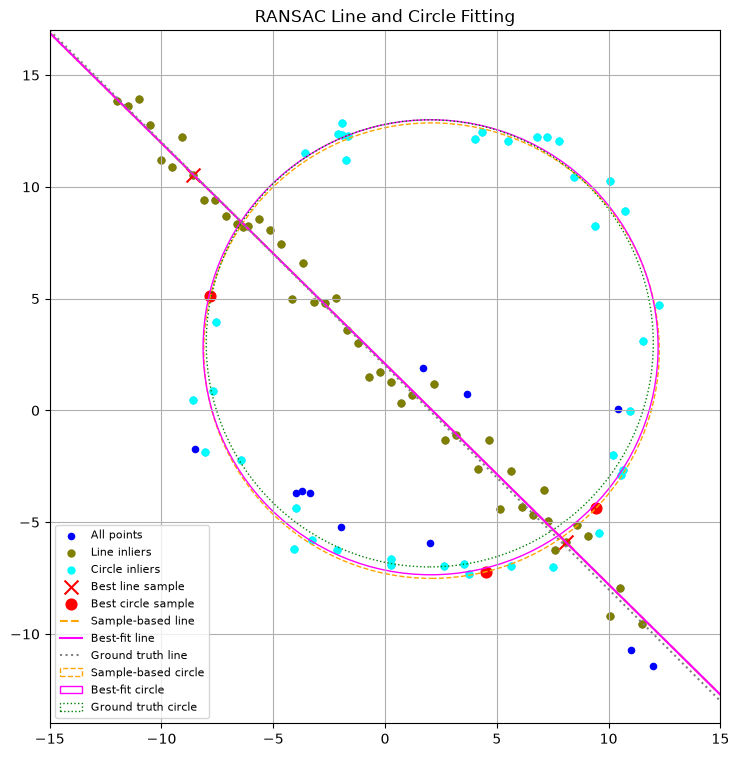

In [101]:
#Q2(c): Plot the complete results
# Q2(c) - Visualize RANSAC results

fig, ax = plt.subplots(figsize=(9, 9))

# All points
ax.scatter(X[:, 0], X[:, 1],s=20, color="blue", label="All points")
# Line inliers
ax.scatter(X[best_line_inliers, 0],X[best_line_inliers, 1],s=25, color="olive", label="Line inliers")
# Circle inliers
ax.scatter(
    remaining_points[best_circle_inliers, 0],
    remaining_points[best_circle_inliers, 1],
    s=25, color="cyan", label="Circle inliers"
)

# RANSAC sample points
ax.scatter(
    best_line_sample[:, 0],
    best_line_sample[:, 1],
    marker="x", s=100, color="red",
    label="Best line sample"
)

ax.scatter(
    best_circle_sample[:, 0],
    best_circle_sample[:, 1],
    marker="o", s=60, color="red",
    label="Best circle sample"
)

# Function to draw a line ax + by = d
def draw_line(model, color, label, style="-"):
    a, b, d = model

    if abs(b) > 1e-10:
        x = np.array([-15, 15])
        y = (d - a*x) / b

        ax.plot(x, y, color=color,linestyle=style, label=label)
    else:
        ax.axvline(d/a, color=color,linestyle=style, label=label)


# Line estimated from the best RANSAC sample
draw_line(best_line_model,"orange","Sample-based line","--")

# Refined line
draw_line(final_line,"magenta","Best-fit line")

# Ground truth line
draw_line(
    np.array([1/np.sqrt(2), 1/np.sqrt(2),
              2/np.sqrt(2)]),
    "gray",
    "Ground truth line",
    ":"
)

# Circle estimated from the best RANSAC sample
sample_circle = plt.Circle(
    best_circle_model[:2],
    best_circle_model[2],
    fill=False,
    color="orange",
    linestyle="--",
    label="Sample-based circle"
)

ax.add_patch(sample_circle)

# Refined circle
fitted_circle = plt.Circle(
    final_circle[:2],
    final_circle[2],
    fill=False,
    color="magenta",
    label="Best-fit circle"
)

ax.add_patch(fitted_circle)

# Ground truth circle
ground_truth_circle = plt.Circle(
    (x0_gt, y0_gt),
    r,
    fill=False,
    color="green",
    linestyle=":",
    label="Ground truth circle"
)

ax.add_patch(ground_truth_circle)

ax.set_xlim(-15, 15)
ax.set_ylim(-14, 17)
ax.set_aspect("equal")
ax.grid(True)

ax.set_title("RANSAC Line and Circle Fitting")
ax.legend(fontsize=8)

plt.savefig(
    "results/q2_ransac.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Q2(d): What happens if we fit the circle first?


The circle RANSAC algorithm would initially receive all 100 points, including the line points.
Because the line points are outliers to the circle, some randomly selected samples would produce incorrect circles. However, RANSAC can still recover the correct circle if the circle has sufficient support and the parameters are chosen appropriately.
Removing the line inliers first reduces the number of interfering points.
An important detail is that fitting the line first can also accidentally remove some circle points near the intersection of the two shapes. Neither fitting order guarantees a perfect result.
For your report, we should ideally test the circle-first approach experimentally, rather than relying only on this explanation.

Question 3 — Homography and Image Superimposition

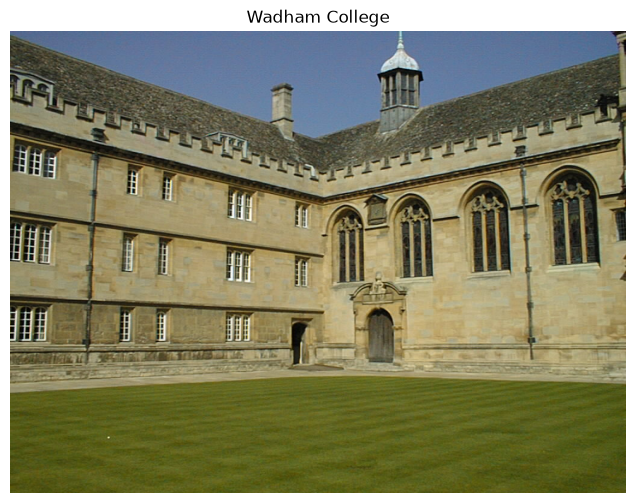

In [102]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

background = cv.imread("images/wadham.jpg")
overlay = cv.imread("images/flag.png")

if background is None or overlay is None:
    raise FileNotFoundError("Image not found. Check paths.")

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(background, cv.COLOR_BGR2RGB))
plt.title("Wadham College")
plt.axis("off")
plt.show()

In [103]:
%matplotlib qt

In [104]:
# Select four points on the building

plt.figure(figsize=(10, 7))

plt.imshow(cv.cvtColor(background, cv.COLOR_BGR2RGB))
plt.title("Click: Top Left, Top Right, Bottom Right, Bottom Left")

points = plt.ginput(4, timeout=0)

dst_points = np.float32(points)

print("Selected points:")
print(dst_points)

plt.close()

Selected points:
[[146.0232  208.95454]
 [128.92487 515.2996 ]
 [520.7616  516.7245 ]
 [516.487   290.1716 ]]


In [105]:
%matplotlib inline

In [106]:
h, w = overlay.shape[:2]

# Four corners of the overlay image
src_points = np.float32([
    [0, 0],
    [w-1, 0],
    [w-1, h-1],
    [0, h-1]
])

# Compute homography
H, _ = cv.findHomography(src_points, dst_points)

# Warp overlay to background perspective
height, width = background.shape[:2]

warped = cv.warpPerspective(
    overlay, H, (width, height)
)

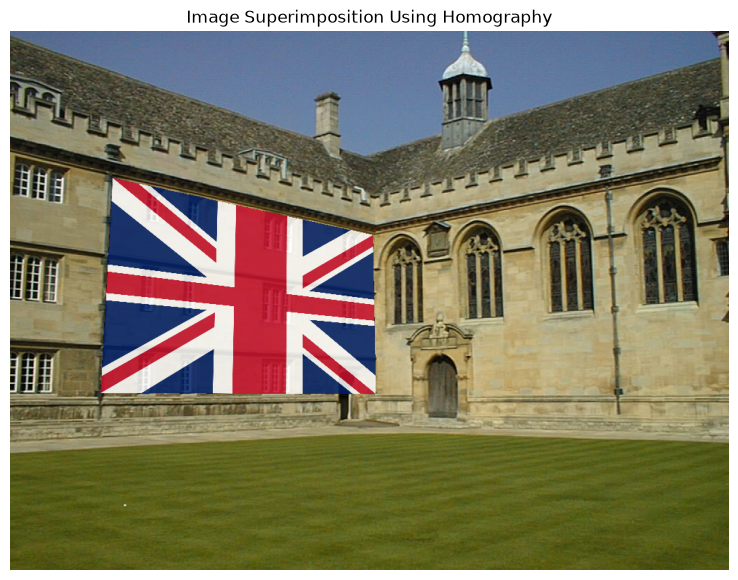

In [107]:
# Create a mask for the warped image
mask = np.ones((h, w), dtype=np.uint8) * 255

warped_mask = cv.warpPerspective(
    mask, H, (width, height)
)

# Blend the overlay into the destination
alpha = 0.85

blended = cv.addWeighted(
    warped, alpha,
    background, 1-alpha,
    0
)

# Apply blending only to the selected region
result = background.copy()

result[warped_mask > 0] = blended[warped_mask > 0]

# Display result
plt.figure(figsize=(10, 7))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("Image Superimposition Using Homography")
plt.axis("off")
plt.show()

In [108]:
cv.imwrite("results/q3_pair1.jpg", result)

True

In [109]:
# Q3 - Homography and Image Superimposition

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("results", exist_ok=True)

def apply_homography(background_path, overlay_path, output_path):

    # Load images
    background = cv.imread(background_path)
    overlay = cv.imread(overlay_path)

    if background is None or overlay is None:
        raise FileNotFoundError("Check image filenames and paths")

    # Select four destination points
    fig, ax = plt.subplots(figsize=(10, 7))

    ax.imshow(cv.cvtColor(background, cv.COLOR_BGR2RGB))
    ax.set_title("Click: Top Left, Top Right, Bottom Right, Bottom Left")

    print("Select 4 points on the background image")

    points = plt.ginput(4, timeout=0)
    plt.close(fig)

    if len(points) != 4:
        raise ValueError("Exactly four points must be selected")

    dst_points = np.float32(points)

    # Four corners of overlay image
    h, w = overlay.shape[:2]

    src_points = np.float32([
        [0, 0],
        [w-1, 0],
        [w-1, h-1],
        [0, h-1]
    ])

    # Compute homography
    H, _ = cv.findHomography(src_points, dst_points)

    # Warp overlay image
    height, width = background.shape[:2]

    warped = cv.warpPerspective(
        overlay, H, (width, height)
    )

    # Create mask for overlay region
    mask = np.ones((h, w), dtype=np.uint8) * 255

    warped_mask = cv.warpPerspective(
        mask, H, (width, height)
    )

    # Blend overlay and background
    alpha = 0.85

    blended = cv.addWeighted(
        warped, alpha,
        background, 1-alpha,
        0
    )

    result = background.copy()
    result[warped_mask > 0] = blended[warped_mask > 0]

    # Save result
    cv.imwrite(output_path, result)

    # Display result
    plt.figure(figsize=(10, 7))
    plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.title("Homography Result")
    plt.axis("off")
    plt.show()

    print("Saved:", output_path)
    print("Homography matrix:\n", H)

    return result





In [119]:
%matplotlib qt

In [120]:
result1 = apply_homography(
    "images/billboard.png",
    "images/flag_lanka.png",
    "results/q3_billboard.png"
)

Select 4 points on the background image
Saved: results/q3_billboard.png
Homography matrix:
 [[ 4.43193873e-01 -9.19156488e-02  1.66201294e+02]
 [ 1.86902239e-01  3.97241537e-01  5.42532463e+01]
 [ 1.98462142e-04 -2.03274658e-04  1.00000000e+00]]


In [121]:
result2 = apply_homography(
    "images/wall.png",
    "images/photo.png",
    "results/q3_pair2.png")

Select 4 points on the background image
Saved: results/q3_pair2.png
Homography matrix:
 [[ 6.93851576e-01  4.21715577e-16  8.13414856e+02]
 [-4.38379512e-01  1.20061041e+00  3.66711609e+02]
 [-6.39603576e-04  3.10893035e-19  1.00000000e+00]]


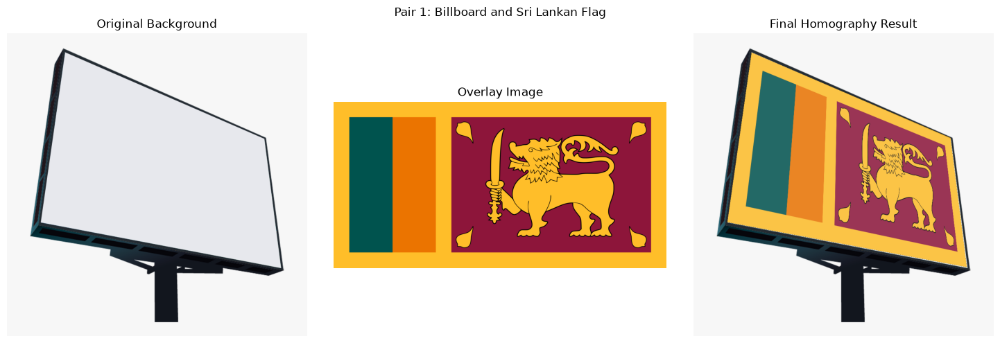

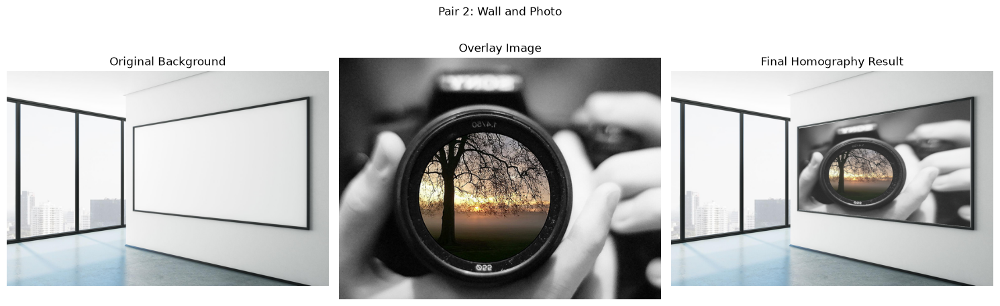

In [122]:
%matplotlib inline

def plot_results(background_path, overlay_path, result, title):

    background = cv.imread(background_path)
    overlay = cv.imread(overlay_path)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(cv.cvtColor(background, cv.COLOR_BGR2RGB))
    axes[0].set_title("Original Background")

    axes[1].imshow(cv.cvtColor(overlay, cv.COLOR_BGR2RGB))
    axes[1].set_title("Overlay Image")

    axes[2].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    axes[2].set_title("Final Homography Result")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# Pair 1 - Billboard + Sri Lankan Flag
plot_results(
    "images/billboard.png",
    "images/flag_lanka.png",
    result1,
    "Pair 1: Billboard and Sri Lankan Flag"
)

# Pair 2 - Wall + Photo
plot_results(
    "images/wall.png",
    "images/photo.png",
    result2,
    "Pair 2: Wall and Photo"
)

Question 4 — PCB Image Alignment and Difference Detection

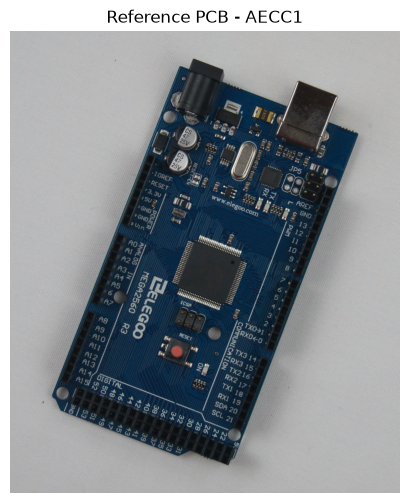

In [123]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

pcb_dir = "images/pcbs"
output_dir = "results/q4"

os.makedirs(output_dir, exist_ok=True)

template = cv.imread(f"{pcb_dir}/AECC1.jpg")

if template is None:
    raise FileNotFoundError("Template AECC1.jpg not found")

template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB))
plt.title("Reference PCB - AECC1")
plt.axis("off")
plt.show()

In [124]:
# SIFT feature detector
sift = cv.SIFT_create()

# BFMatcher
bf = cv.BFMatcher(cv.NORM_L2)

# Detect template features
kp1, des1 = sift.detectAndCompute(template_gray, None)


def align_pcb(image_path):

    target = cv.imread(image_path)

    if target is None:
        raise FileNotFoundError(image_path)

    target_gray = cv.cvtColor(target, cv.COLOR_BGR2GRAY)

    # Detect SIFT features in target
    kp2, des2 = sift.detectAndCompute(target_gray, None)

    if des1 is None or des2 is None or len(des2) < 2:
        raise ValueError("Not enough SIFT features")

    # Match descriptors
    matches = bf.knnMatch(des2, des1, k=2)

    # Lowe's ratio test
    good_matches = [
        m for m, n in matches
        if m.distance < 0.75 * n.distance
    ]

    if len(good_matches) < 4:
        raise ValueError("Not enough good matches")

    # Corresponding feature coordinates
    src_pts = np.float32([
        kp2[m.queryIdx].pt for m in good_matches
    ]).reshape(-1, 1, 2)

    dst_pts = np.float32([
        kp1[m.trainIdx].pt for m in good_matches
    ]).reshape(-1, 1, 2)

    # Estimate homography using RANSAC
    H, mask = cv.findHomography(
        src_pts, dst_pts,
        cv.RANSAC, 5.0
    )

    if H is None:
        raise ValueError("Homography estimation failed")

    # Draw feature matches
    match_image = cv.drawMatches(
        target, kp2,
        template, kp1,
        good_matches, None,
        matchesMask=mask.ravel().tolist(),
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # Warp target image to template coordinates
    height, width = template.shape[:2]

    aligned = cv.warpPerspective(
        target, H, (width, height)
    )

    # Valid warped region
    valid_mask = cv.warpPerspective(
        np.ones(target_gray.shape, dtype=np.uint8) * 255,
        H, (width, height)
    )

    # Compute absolute difference
    difference = cv.absdiff(template, aligned)

    # Exclude pixels outside the warped target
    difference[valid_mask == 0] = 0

    return target, match_image, aligned, difference

Processing AAAA1.jpg...


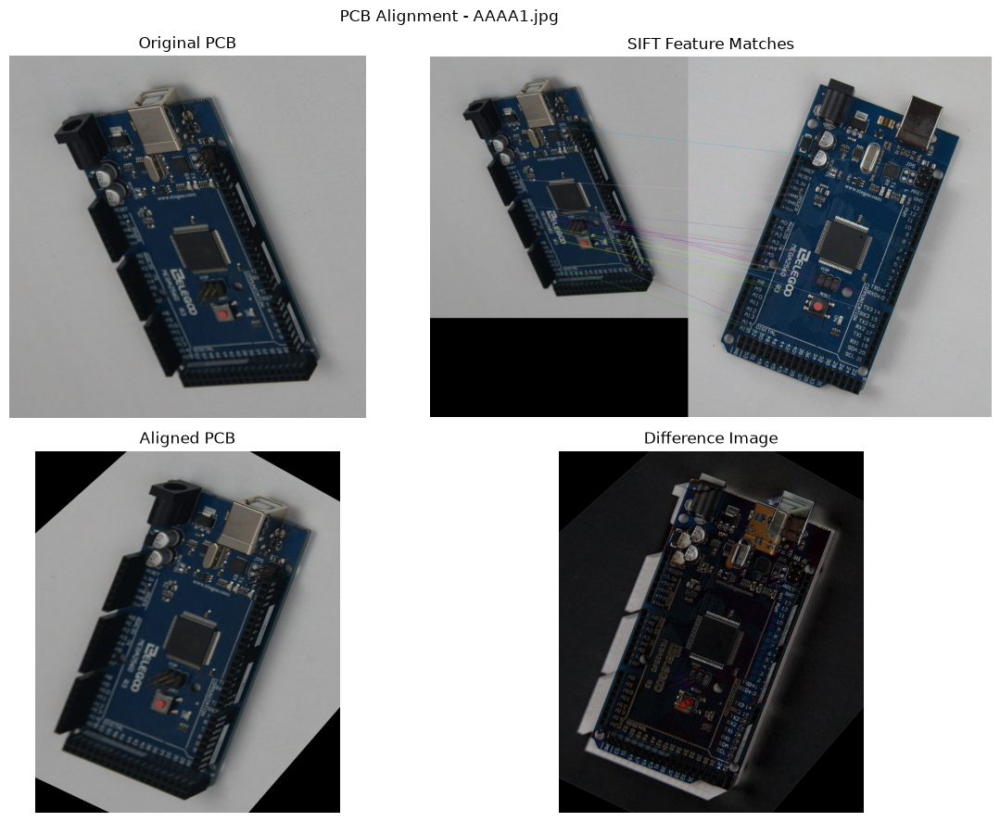

Processing ADAD1.jpg...


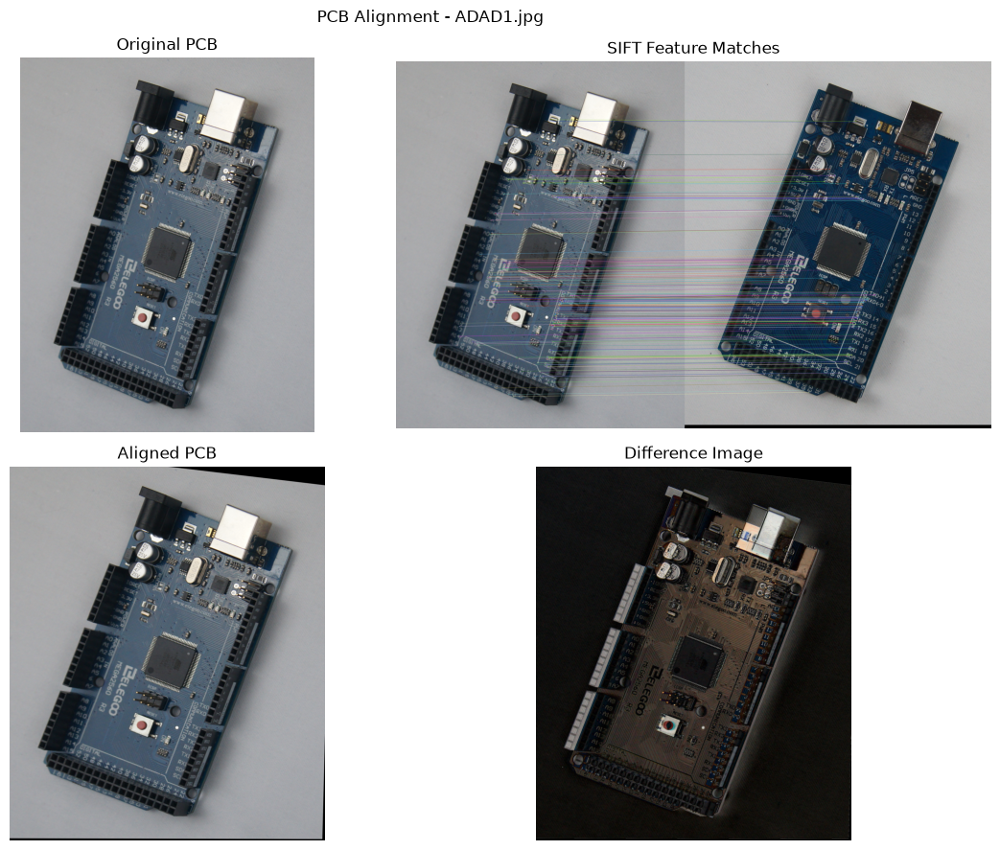

Processing AECC2.jpg...


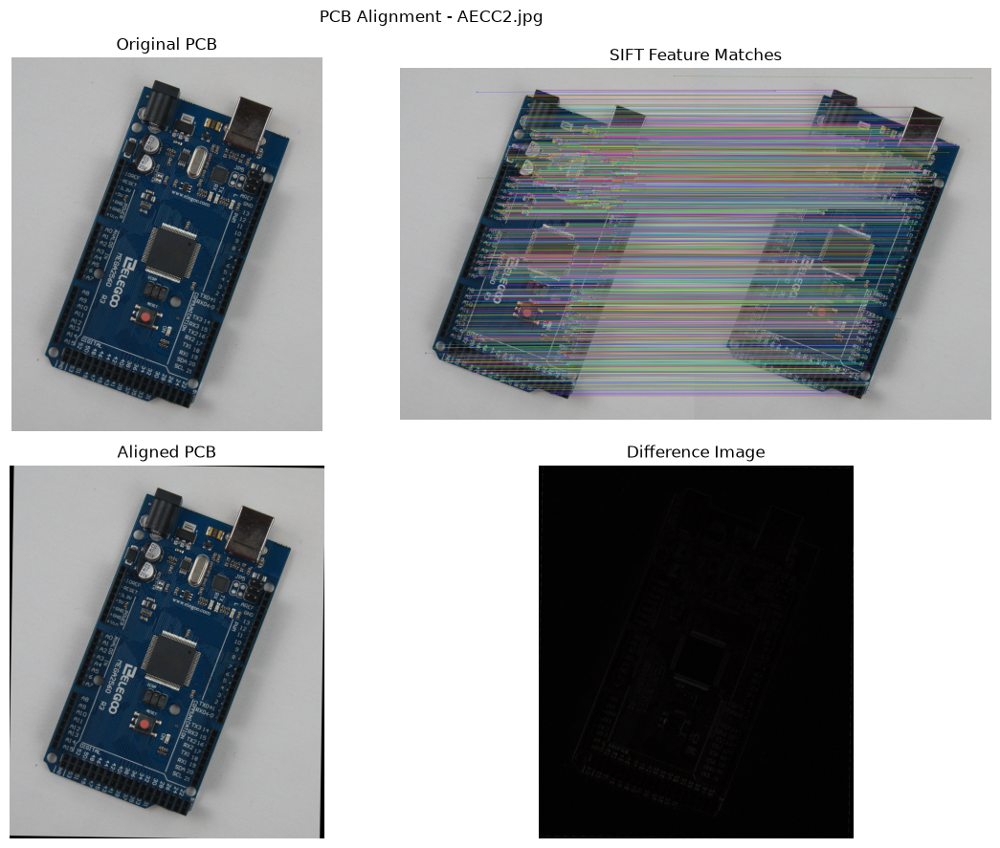

Processing AECC3.jpg...


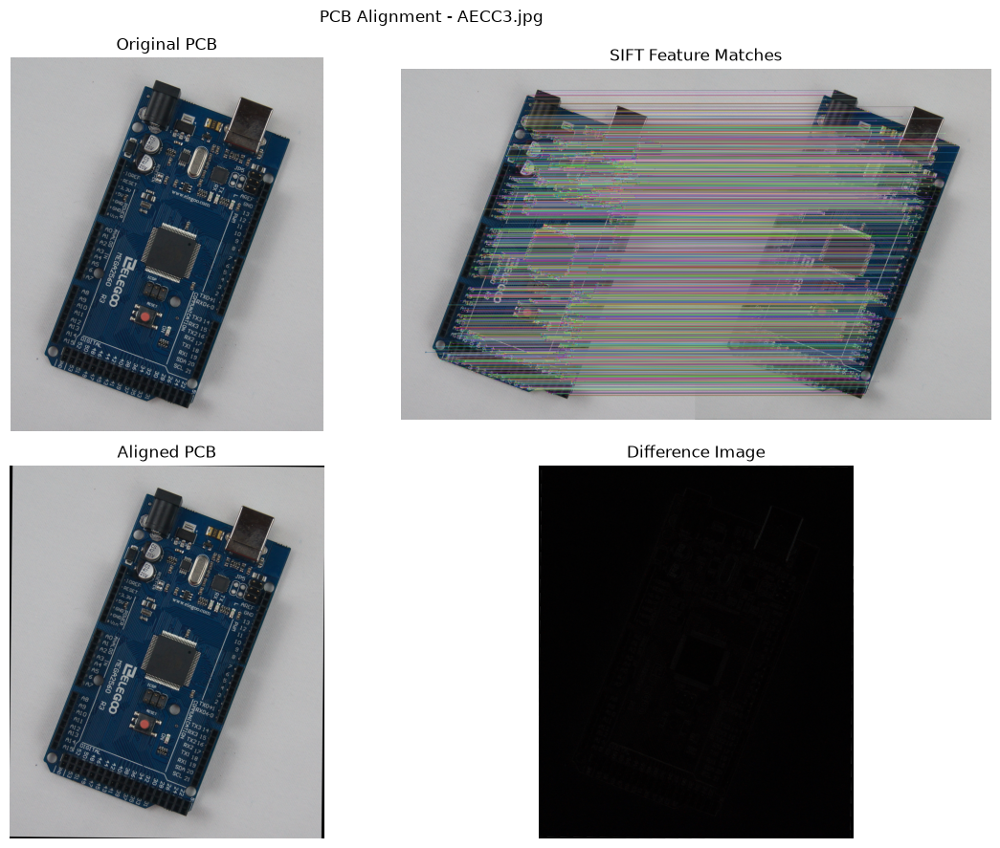

Processing AECC4.jpg...


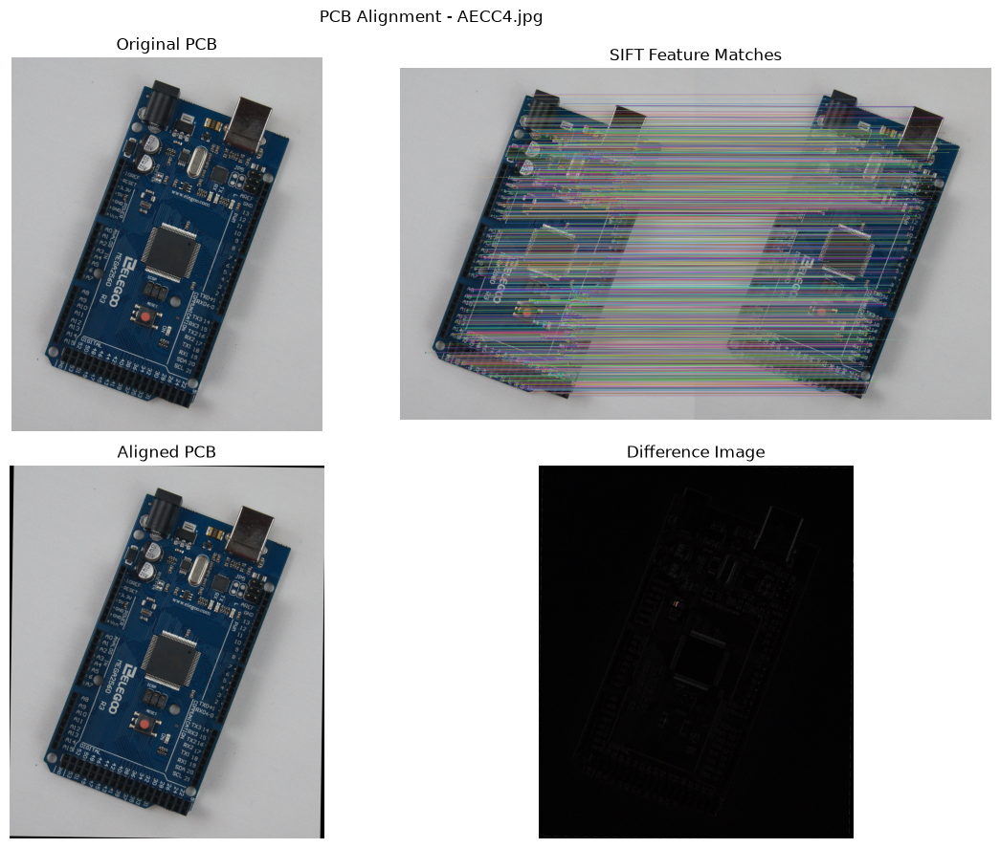

In [125]:
# Q4(c) and Q4(d) - Process all PCB images

pcb_files = [
    "AAAA1.jpg",
    "ADAD1.jpg",
    "AECC2.jpg",
    "AECC3.jpg",
    "AECC4.jpg"
]

for filename in pcb_files:

    print(f"Processing {filename}...")

    image_path = f"{pcb_dir}/{filename}"
    name = os.path.splitext(filename)[0]

    try:
        target, matches, aligned, difference = align_pcb(image_path)

        # Save outputs
        cv.imwrite(f"{output_dir}/{name}_matches.png", matches)
        cv.imwrite(f"{output_dir}/{name}_aligned.png", aligned)
        cv.imwrite(f"{output_dir}/{name}_difference.png", difference)

        # Plot results
        fig, axes = plt.subplots(2, 2, figsize=(12, 9))

        axes[0, 0].imshow(cv.cvtColor(target, cv.COLOR_BGR2RGB))
        axes[0, 0].set_title("Original PCB")

        axes[0, 1].imshow(cv.cvtColor(matches, cv.COLOR_BGR2RGB))
        axes[0, 1].set_title("SIFT Feature Matches")

        axes[1, 0].imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB))
        axes[1, 0].set_title("Aligned PCB")

        axes[1, 1].imshow(
            cv.cvtColor(difference, cv.COLOR_BGR2RGB)
        )
        axes[1, 1].set_title("Difference Image")

        for ax in axes.flat:
            ax.axis("off")

        plt.suptitle(f"PCB Alignment - {filename}")
        plt.tight_layout()

        plt.savefig(
            f"{output_dir}/{name}_comparison.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

    except (ValueError, FileNotFoundError, cv.error) as e:
        print(f"Failed for {filename}: {e}")

Question 4(e) — Why do certain components show high differences?


Components such as the USB Type-B port, capacitors, and reset button are three-dimensional structures.
When PCB photographs are taken from different viewing angles:
- Parallax: Raised components appear shifted relative to the PCB surface.
- Lighting differences: Reflections and shadows change between images.
- Perspective effects: A single homography aligns the planar PCB surface but cannot perfectly align objects at different heights.
Therefore, these components can show large differences even when the PCB itself is correctly aligned.